# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import MSOSCDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Original split

In [ ]:
# specific bands
dataset_config = {
    "data_dir" : "./data/msoscd/",
    "mode": "train",
    "imagery": "all",
    "selection": "bands",
    "bands_s2": ["B02","B03","B04","B08"],
    "bands_s1": ["VV"]
}
dataset = MSOSCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 3805


Total number of patches: 3805


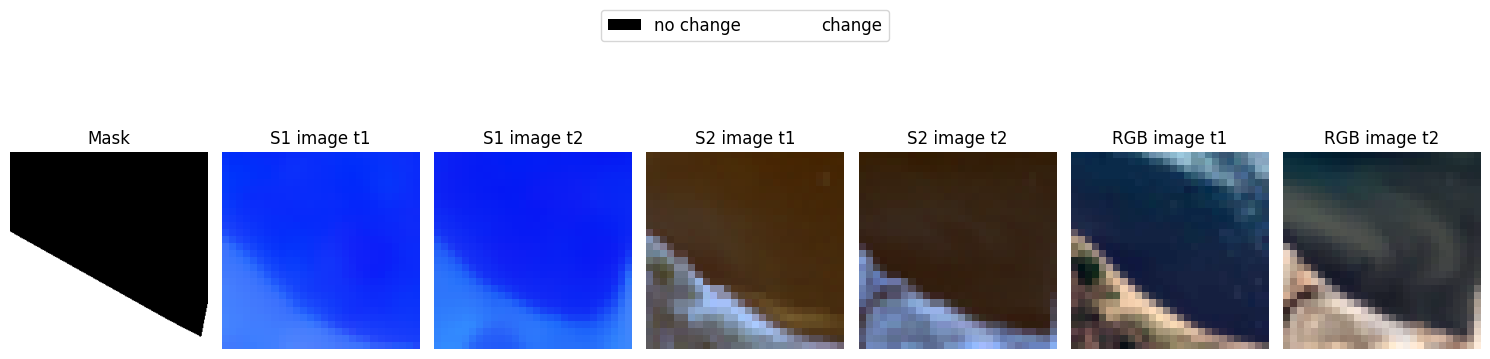

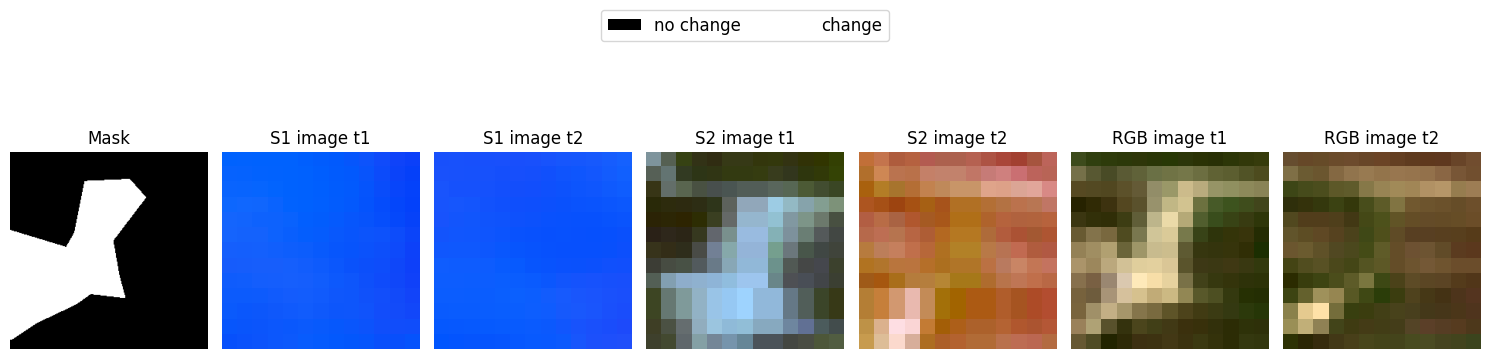

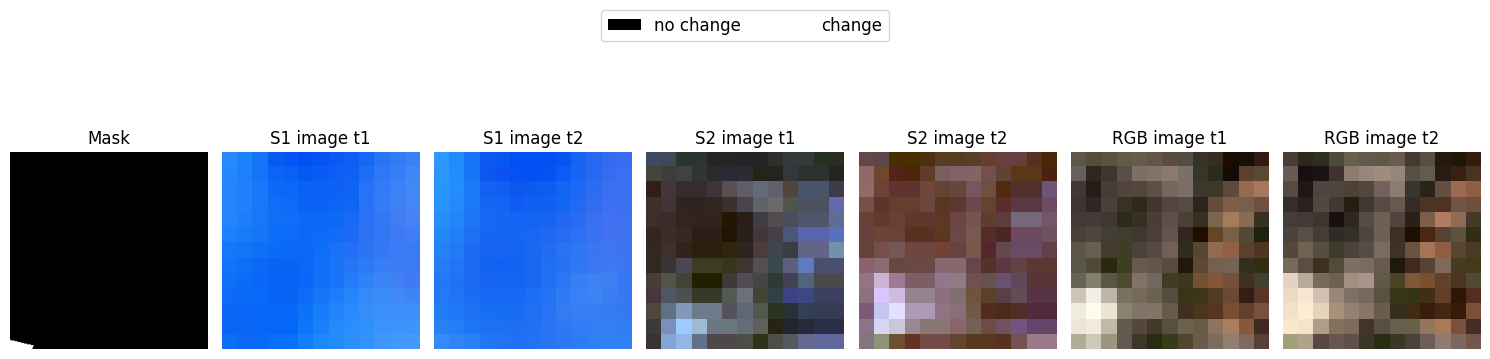

In [ ]:
# rgb images
dataset_config = {
    "data_dir" : "./data/msoscd/",
    "selection": "rgb",
    "mode": "train",
    "imagery": "all" # note: the aerial RGB image is resampled to the Sentinel size
}
dataset = MSOSCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1);
dataset.show_image(150);
dataset.show_image(1000);

Total number of patches: 3805


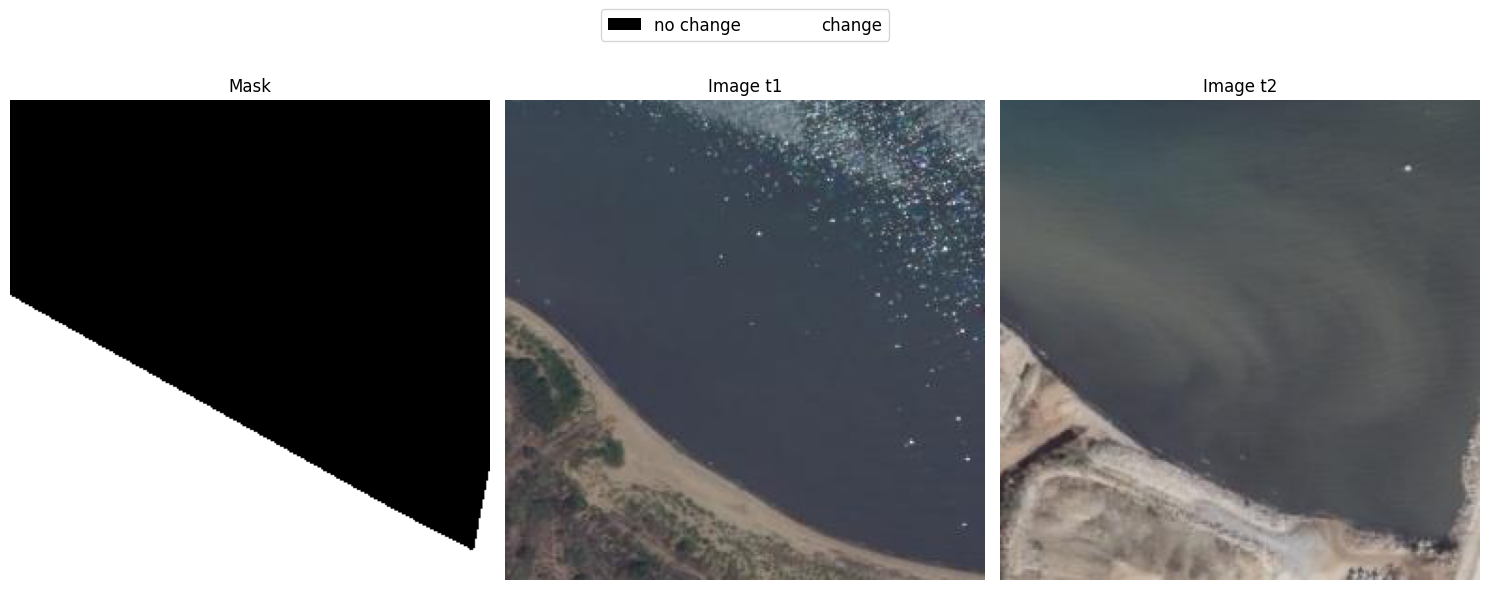

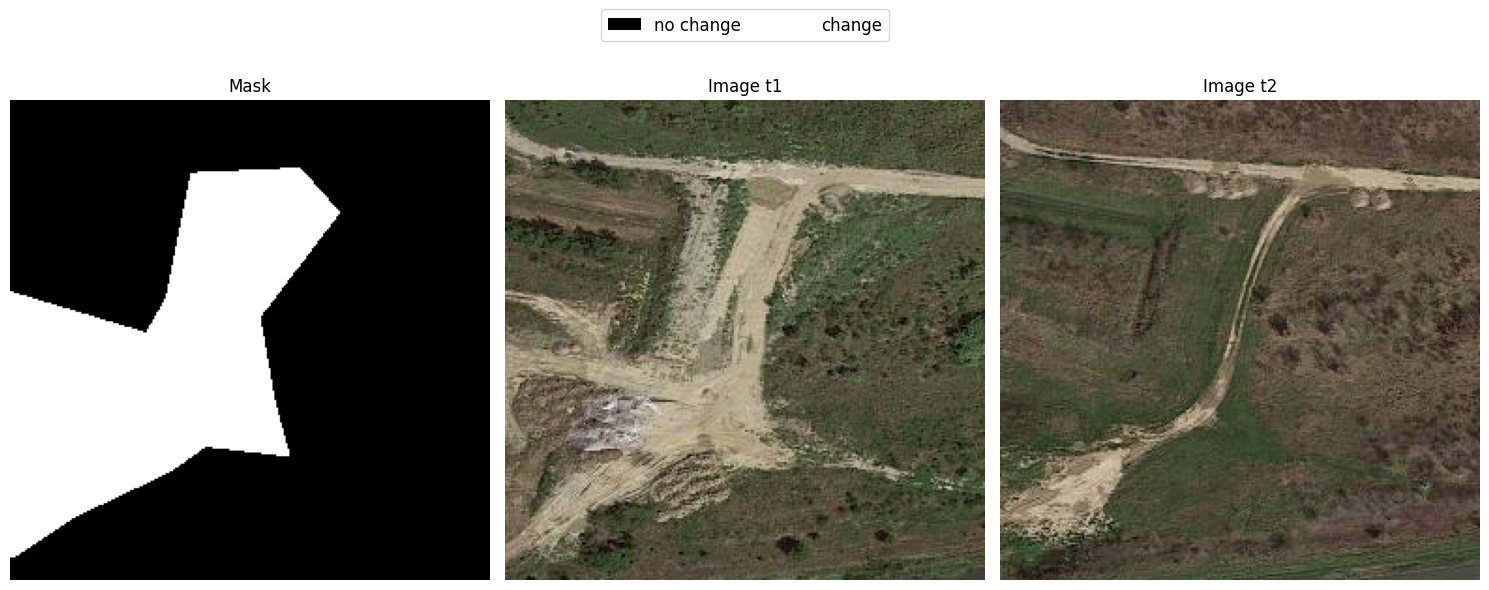

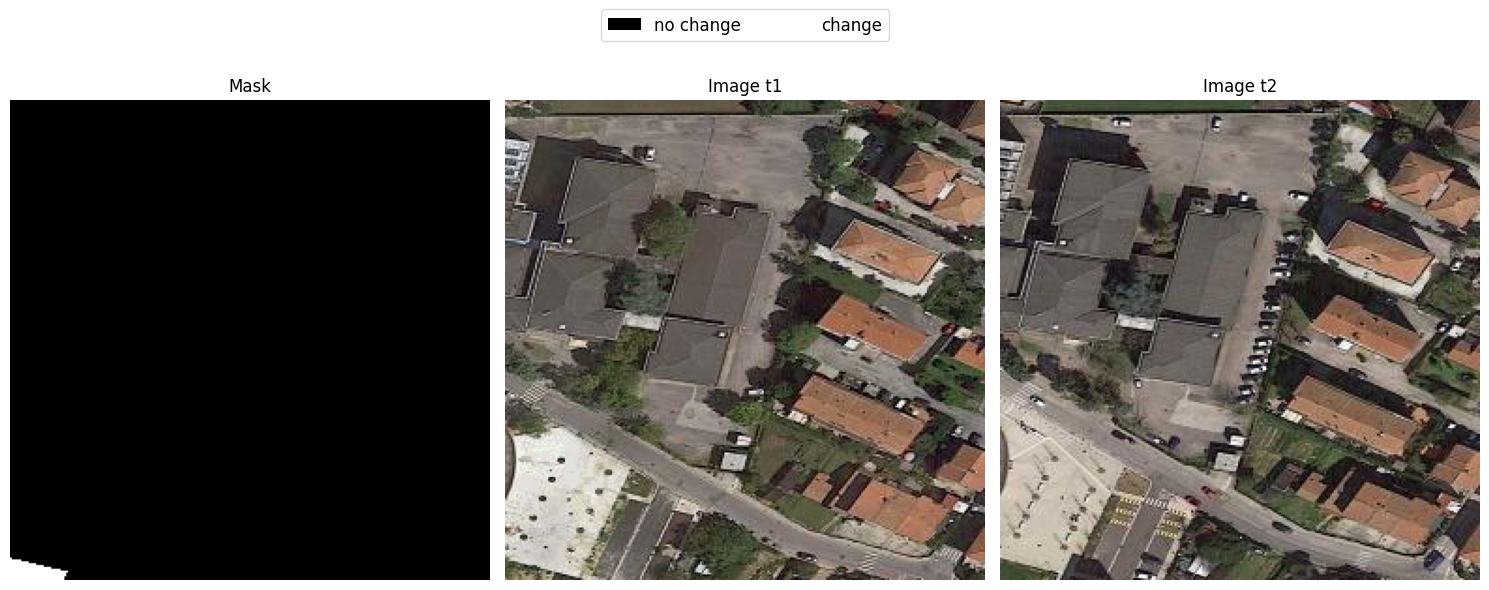

In [ ]:
dataset_config = {
    "data_dir" : "./data/msoscd/",
    "selection": "rgb",
    "mode": "train",
    "imagery": "aerial" # aerial RGB images in their original size
}
dataset = MSOSCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1);
dataset.show_image(150);
dataset.show_image(1000);

In [9]:
dataset.data_distribution_table()

,Number of pixels
no change,204718799.0
change,44645681.0


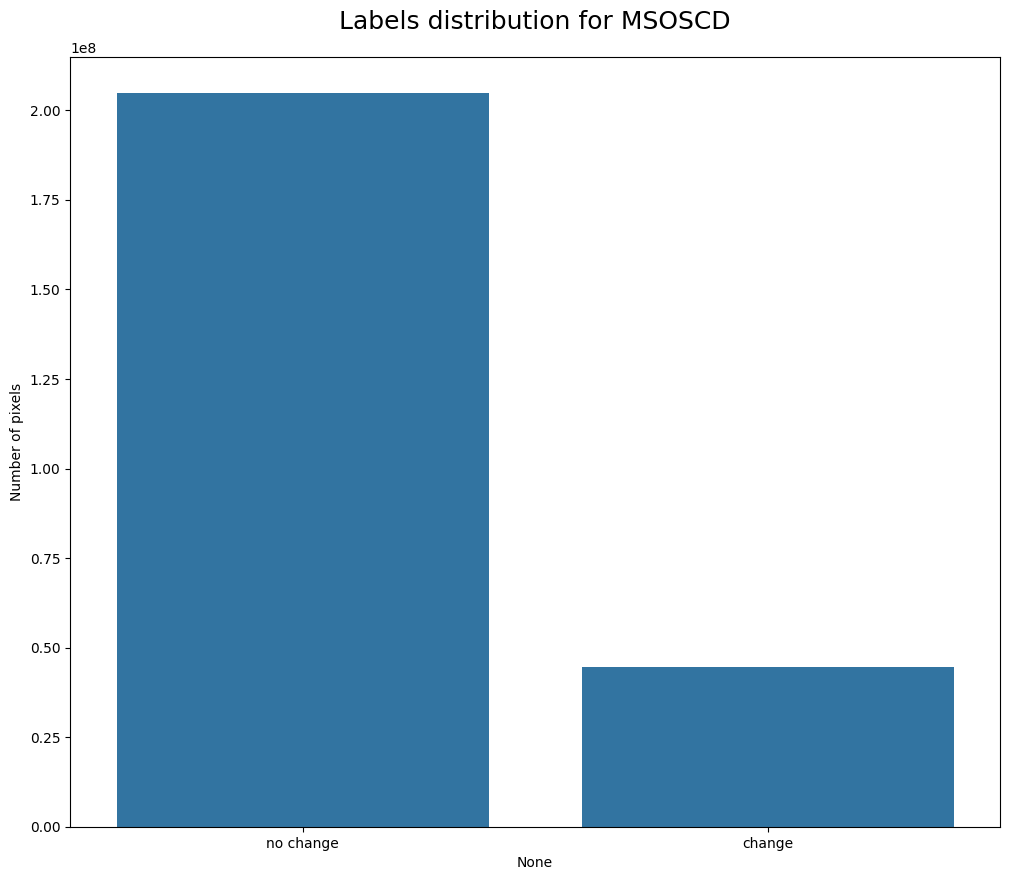

In [9]:
dataset.data_distribution_barchart();

New 60/20/20 split

Total number of patches: 3064


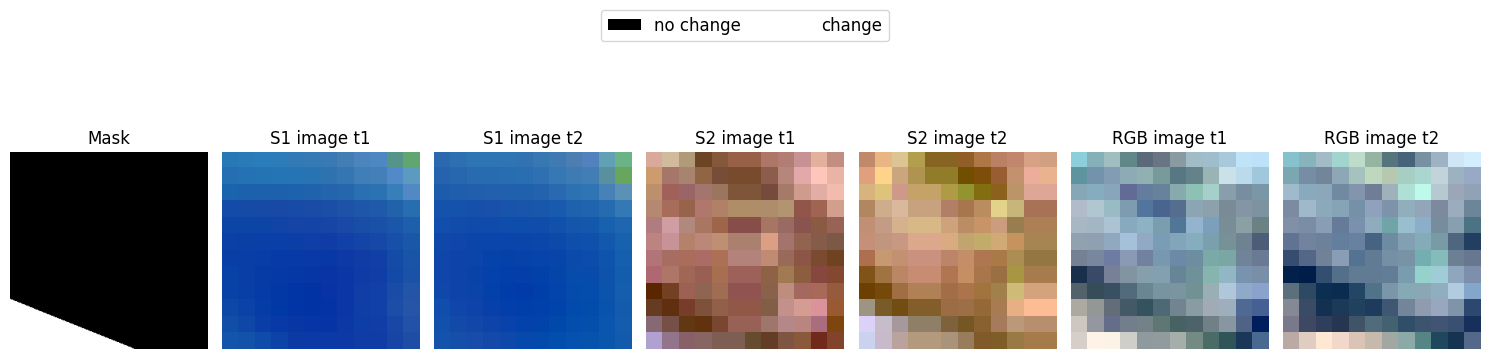

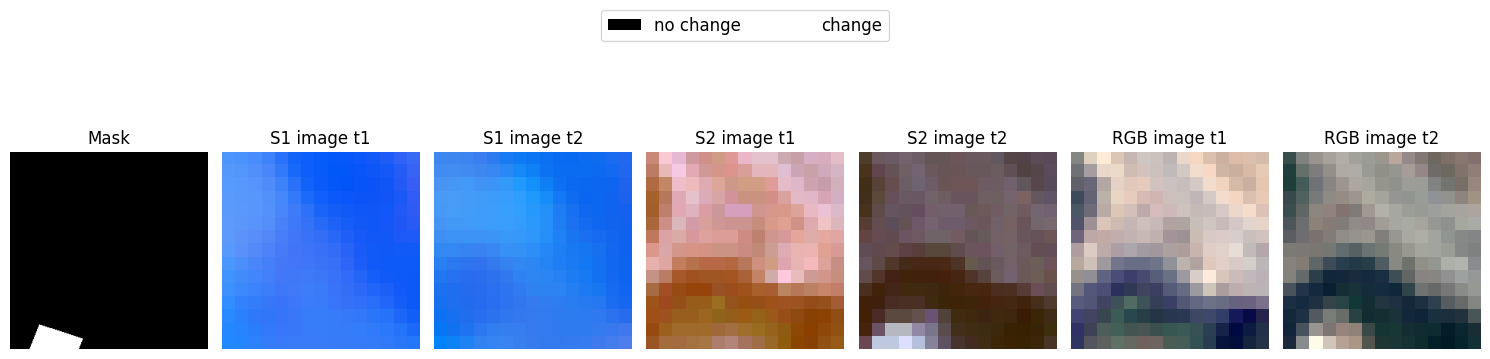

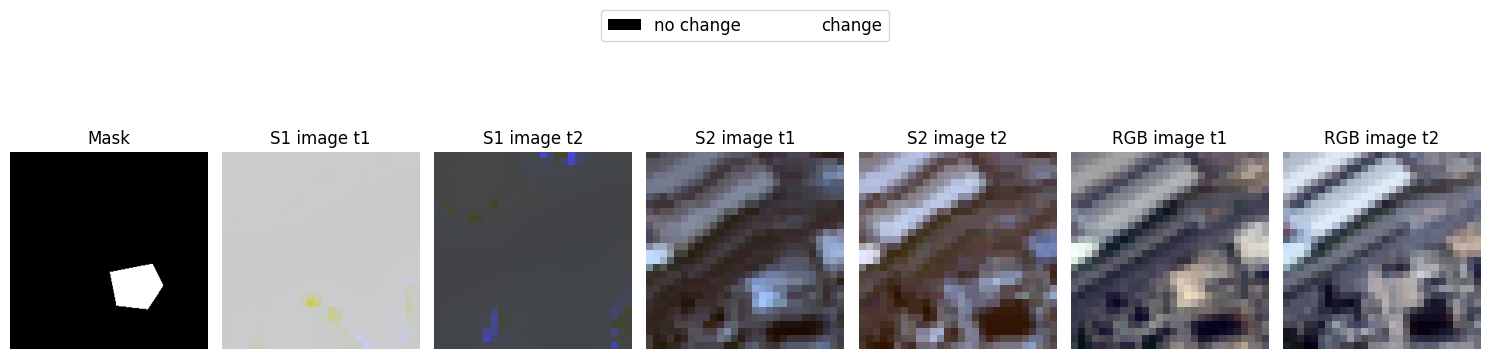

In [ ]:
dataset_config = {
    "data_dir" : "./data/msoscd/",
    "csv_file": "./data/msoscd/msoscd_train.csv",
    "selection": "rgb",
    "imagery": "all"
}
dataset = MSOSCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1);
dataset.show_image(150);
dataset.show_image(1000);

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/msoscd/",
    "csv_file": "./data/msoscd/msoscd_train.csv",
    "selection": "rgb",
    "imagery": "aerial", # can be changed to s1, s2 or all
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = MSOSCDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/msoscd/",
    "csv_file": "./data/msoscd/msoscd_val.csv",
    "selection": "rgb",
    "imagery": "aerial",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = MSOSCDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(3064, 1021)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/msoscd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [21]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-29 08:27:55,313 INFO Starting training.
training: 100%|██████████| 192/192 [00:47<00:00,  4.03it/s]
2026-01-29 08:28:43,121 INFO epoch: 1, loss:  0.21718
testing on train set: 100%|██████████| 192/192 [00:16<00:00, 11.58it/s]
2026-01-29 08:29:00,960 INFO Accuracy:0.8681209479548602, Accuracy per Class:[0.86903736 0.86720453], Precision Micro:0.8663070864905983, Precision Macro:0.7776960709632941, Precision Weighted:0.8608956370338064, Precision per Class:[0.90772086 0.64767128], Recall Micro:0.8705968234308706, Recall Macro:0.7555126241136187, Recall Weighted:0.8705968234308705, Recall per Class:[0.93536691 0.57565834], F1_score Micro:0.8684466576489738, F1_score Macro:0.7654408911015054, F1_score Weighted:0.8651945663016167, F1_score per Class:[0.92133654 0.60954524], IOU:0.7674818544962314, IOU mean:0.6462623810024906, IOU per Class:[0.85414643 0.43837834]
training: 100%|██████████| 192/192 [00:47<00:00,  4.07it/s]
2026-01-29 08:29:48,112 INFO epoch: 2, loss:  0.15661
testing

## Predictions

2026-01-29 09:08:43,055 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/msoscd/checkpoint.pth.tar
2026-01-29 09:08:43,419 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/msoscd/checkpoint.pth.tar at epoch 51


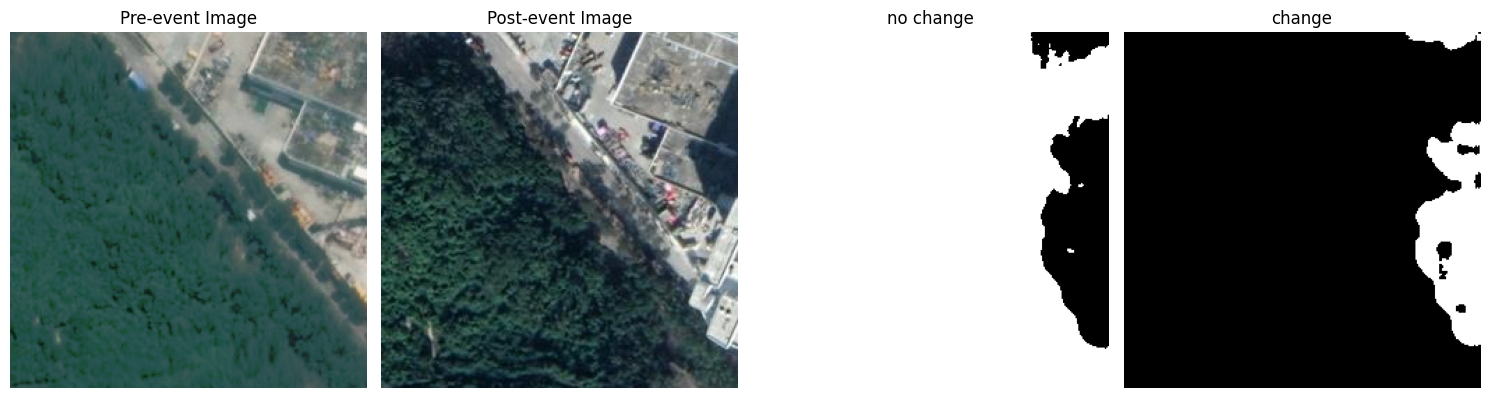

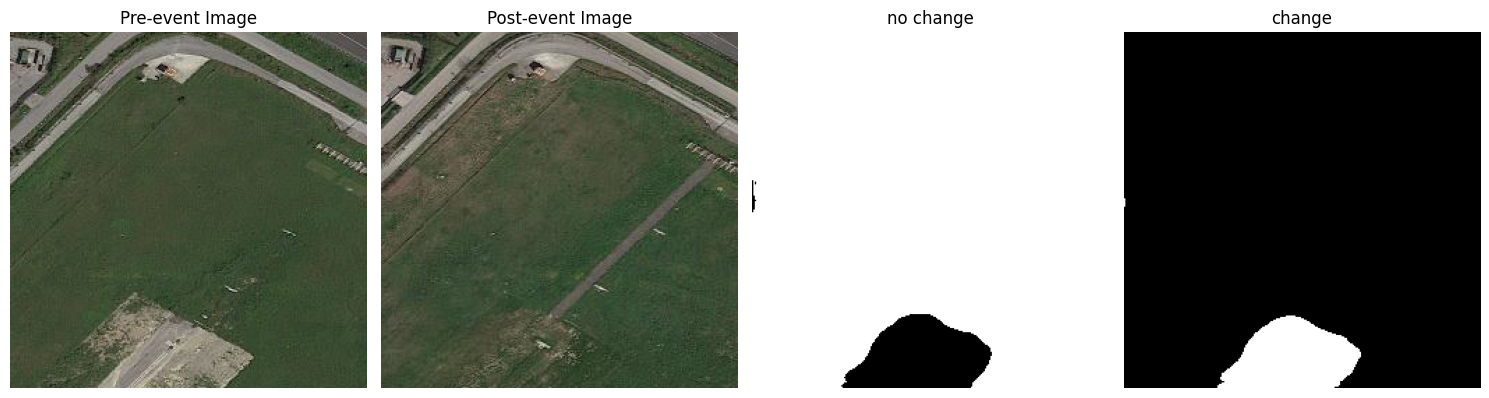

In [ ]:
model_path = "./data/experiments/msoscd/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("./data/msoscd/test/rgb1/2545.tif")
image2 = image_loader("./data/msoscd/test/rgb2/2545.tif")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("./data/msoscd/test/rgb1/3559.tif")
image2 = image_loader("./data/msoscd/test/rgb2/3559.tif")
fig = model.predict_masks(image1, image2, labels, transform)